# XAU/USD forecasting with ARIMA

Standalone adaptation of the matching `BTC_TEST` notebook and the `time-series-forecasting` skill. Source: `CSV/XAU_USD Historical Data.csv`; target: `Price`; units: **USD (source price)**.

**Flow:** source audit → raw chronological 80/20 Train/Test (no validation) → descriptive EDA → Train-only development and diagnostics → frozen rolling-origin Test forecasts → separate latest-origin future forecasts → RMSE/MAPE by horizon → plots and execution-generated summary.

**Asset adaptation declared before Test:** horizons [1, 5, 10, 20] count successive **observations**, not calendar days or a guaranteed month. Window models use 40 observed returns (roughly eight 5-day weeks, or fewer weeks for the WTI source). No artificial weekend/holiday prices. The supplied CSV has no exchange-calendar metadata; missing dates are disclosed. Future dates are projected from a declared weekday pattern and are not confirmed exchange sessions.

Run all cells from a fresh **Python 3.12 (vs_nine TensorFlow)** kernel using `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`. Versions and actual executable are printed and saved. Output: `OUTPUT/ARIMA_XAU/{tables,figures,summaries,models}`.

The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.

**Horizon update:** `[1, 3, 5, 7, 14, 21, 30]` observed steps, as explicitly requested by the user. Previous cell outputs were cleared. Restart the kernel and run all cells to regenerate models, forecasts, metrics and exported results for this configuration; existing files in OUTPUT still belong to the previous execution until rerun.


## 1. Imports and environment

In [1]:
from pathlib import Path
import os, sys, json, random, hashlib, warnings, time
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import joblib
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display, Markdown, HTML

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

## 2. Single configuration cell
All experiment settings are declared before Test inference. These are reference-informed fixed settings, not claimed asset-specific optima. Change them only as a new, explicitly documented experiment after viewing Test.

In [2]:
ASSET = 'XAU'
ASSET_NAME = 'XAU/USD'
MODEL = 'ARIMA'
UNIT = 'USD (source price)'
ASSET_NOTE = 'The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.'
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CSV' / 'XAU_USD Historical Data.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Start Jupyter in PROJECT_2026 or the asset notebook folder.')
DATA_PATH = PROJECT_ROOT / 'CSV' / 'XAU_USD Historical Data.csv'
DATE_COL, TARGET_COL, DATE_FORMAT = 'Date', 'Price', '%m/%d/%Y'
TRAIN_RATIO = 0.8
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
LOOKBACK = 40
TRANSFORMATION = 'log price for ARIMA; observed-step log returns for feature/MIMO models'
WEEKMASK = 'Mon Tue Wed Thu Fri'
CALENDAR_NOTE = 'Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.'
CALENDAR_POLICY_USER_ACKNOWLEDGED = False
SEEDS = [0]
ALPHA = 0.05
DIAGNOSTIC_LAGS = [10,20,30]
ROLLING_WINDOW = 20
SETTINGS = {'max_p': 3, 'max_q': 3, 'max_d': 2, 'maxiter': 200, 'selection': 'minimum AIC among converged finite-AIC root-valid fits; residual diagnostics report only'}
PACKAGES = ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'scikit-learn', 'joblib']
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)


## 3. Output helpers, provenance and diagnostics
Process checks enforce chronology, leakage prevention and frozen fitted state. Statistical diagnostics with no declared selection threshold are marked **REPORTED**. No statistical test on Test controls tuning or refitting.

In [3]:
assert HORIZONS == sorted(set(HORIZONS)) and min(HORIZONS) >= 1
MAX_H = max(HORIZONS)
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / f'{MODEL}_{ASSET}'
TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR = [OUTPUT_DIR / k for k in ['tables','figures','summaries','models']]
for directory in [TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .2})
def save_table(frame, name): frame.to_csv(TABLE_DIR / name, index=False, encoding='utf-8-sig')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def show_table(frame):
    display(HTML('<div style="max-height:340px;overflow:auto;border:1px solid #ddd">' +
                 frame.to_html(index=False, float_format=lambda x: f'{x:,.6f}') + '</div>'))
def write_json(path, obj): path.write_text(json.dumps(obj, indent=2, default=str, ensure_ascii=False), encoding='utf-8')
def markdown_table(frame):
    def cell(x):
        if isinstance(x,(float,np.floating)): return f'{x:.6f}'
        return str(x).replace('|','/').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
        '| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(cell(x) for x in row)+' |' for row in frame.itertuples(index=False,name=None)])
def warning_text(caught): return ' | '.join(f'{w.category.__name__}: {w.message}' for w in caught)
versions = pd.DataFrame([(p, version(p)) for p in PACKAGES], columns=['library','version'])
save_table(versions, 'library_versions.csv')
display(versions)
print('Python:', sys.version, '\nExecutable:', sys.executable, '\nData:', DATA_PATH, '\nOutput:', OUTPUT_DIR)
configuration = dict(asset=ASSET, model=MODEL, data=str(DATA_PATH), target=TARGET_COL, date_column=DATE_COL,
    date_format=DATE_FORMAT, unit=UNIT, asset_note=ASSET_NOTE, train_ratio=TRAIN_RATIO,
    horizons=HORIZONS, daily_forecast_windows=DAILY_FORECAST_WINDOWS, horizon_unit='observations', calendar=CALENDAR_NOTE, weekmask=WEEKMASK,
    lookback=LOOKBACK, transformation=TRANSFORMATION, seeds=SEEDS, settings=SETTINGS,
    alpha=ALPHA, validation=False, evaluation='rolling origins from final Train row; frozen fitted parameters',
    design_source='BTC_TEST implementation reference + time-series-forecasting skill; asset-specific adaptation declared before Test',
    python_executable=sys.executable, python_version=sys.version)
write_json(SUMMARY_DIR / 'configuration.json', configuration)
process_rows = []
def check(name, condition, note='', statistic=None):
    process_rows.append(dict(check=name, statistic=statistic, p_value=np.nan,
                             status='PASS' if bool(condition) else 'FAIL', interpretation=note))
    save_table(pd.DataFrame(process_rows), 'process_checks.csv')
    assert condition, f'{name}: {note}'
def residual_report(values, label, model_df=0):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    rows = []
    lags = [lag for lag in DIAGNOSTIC_LAGS if model_df < lag < len(values)//2]
    lb = acorr_ljungbox(values, lags=lags, model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        rows.append(dict(sample=label, check=f'Ljung-Box lag {lag}', statistic=row.lb_stat,
            p_value=row.lb_pvalue, status='REPORTED', interpretation=('Evidence of serial correlation' if row.lb_pvalue <= ALPHA else 'No rejection of residual independence') + f'; model_df={model_df}; reporting only'))
    t, p = stats.ttest_1samp(values, 0.)
    rows.append(dict(sample=label, check='Residual mean t-test', statistic=t, p_value=p, status='REPORTED',
        interpretation=f'Mean={values.mean():.8g}; descriptive, dependent errors limit the t-test'))
    lm, p, _, _ = het_arch(values, nlags=min(10, len(values)//5), ddof=model_df)
    rows.append(dict(sample=label, check='ARCH LM', statistic=lm, p_value=p, status='REPORTED',
        interpretation='Conditional variance evidence; no retuning'))
    jb, p, skew, kurt = jarque_bera(values)
    rows.append(dict(sample=label, check='Jarque-Bera', statistic=jb, p_value=p, status='REPORTED',
        interpretation=f'Normality diagnostic; skew={skew:.5g}; kurtosis={kurt:.5g}; no retuning'))
    return pd.DataFrame(rows)

,library,version
0,numpy,2.5.3
1,pandas,2.3.3
2,matplotlib,3.11.1
3,scipy,1.18.1
4,statsmodels,0.15.0
5,scikit-learn,1.9.1
6,joblib,1.6.0


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\XAU_USD Historical Data.csv 
Output: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_XAU


## 4. Source audit and preparation
Parse US-style dates and comma-separated prices. Stop on invalid or duplicate targets. Do not resample or silently fill/drop source observations. Auxiliary OHLC/volume columns are not features. The date-gap audit distinguishes observed records from unverified holidays or omissions.

In [4]:
raw = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig')
assert {DATE_COL,TARGET_COL}.issubset(raw.columns)
dates = pd.to_datetime(raw[DATE_COL], format=DATE_FORMAT, errors='coerce')
price = pd.to_numeric(raw[TARGET_COL].str.replace(',', '', regex=False).str.strip(), errors='coerce')
invalid = dates.isna() | ~np.isfinite(price) | price.le(0)
duplicates = dates.duplicated(keep=False)
save_table(raw.loc[invalid | duplicates], 'invalid_or_duplicate_source_rows.csv')
check('Valid dates, finite strictly positive targets, unique dates', not (invalid | duplicates).any(),
      'Log representation was predetermined; stop rather than impute, drop, or offset invalid targets.')
df = pd.DataFrame({'Date': dates, 'Price': price}).sort_values('Date').set_index('Date')
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
T = n_train - 1
prices = df.Price.to_numpy()
log_price = np.log(prices)
returns = np.r_[np.nan, np.diff(log_price)]
check('Chronological raw 80/20 partition', df.index.is_monotonic_increasing and df.index.is_unique and n_train == int(.8*n),
      'No shuffling, validation partition, or target imputation.')
check('Sufficient Train/Test history', n_train > LOOKBACK + MAX_H + 10 and n_test >= MAX_H,
      'Requested horizons and lookback must remain feasible without shortening.')
source_order = 'descending' if dates.is_monotonic_decreasing else ('ascending' if dates.is_monotonic_increasing else 'mixed')
calendar_offset = pd.offsets.CustomBusinessDay(weekmask=WEEKMASK)
expected_calendar = pd.date_range(df.index[0], df.index[-1], freq=calendar_offset)
missing_dates = expected_calendar.difference(df.index)
unexpected_dates = df.index.difference(expected_calendar)
save_table(pd.DataFrame({'date': missing_dates, 'classification': 'not observed; holiday/omission unknown; no imputation'}), 'calendar_missing_dates.csv')
save_table(pd.DataFrame({'date': unexpected_dates}), 'calendar_unexpected_dates.csv')
gaps = pd.DataFrame({'previous_date': df.index[:-1], 'next_date': df.index[1:],
                     'calendar_days': np.diff(df.index.values).astype('timedelta64[D]').astype(int)})
save_table(gaps, 'observation_gaps.csv')
quality = pd.DataFrame([dict(rows=n, source_order=source_order, invalid_targets=int(invalid.sum()),
    duplicate_dates=int(duplicates.sum()), nonpositive_targets=int(price.le(0).sum()),
    missing_relative_to_weekmask=len(missing_dates), unexpected_weekdays=len(unexpected_dates),
    maximum_calendar_gap=int(gaps.calendar_days.max()), volume_missing=int(raw['Vol.'].isna().sum()) if 'Vol.' in raw else None,
    first_date=df.index[0], last_date=df.index[-1], source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    gap_policy=CALENDAR_NOTE)])
save_table(quality, 'data_quality.csv')
save_table(df.reset_index(), 'prepared_target.csv')
display(quality.T)
show_table(gaps.loc[gaps.calendar_days.gt(3)])
show_table(pd.DataFrame({'unobserved_date': missing_dates}))
print(ASSET_NOTE)
print(CALENDAR_NOTE)
print('Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.')

,0
rows,1333
source_order,descending
invalid_targets,0
duplicate_dates,0
nonpositive_targets,0
missing_relative_to_weekmask,5
unexpected_weekdays,0
maximum_calendar_gap,4
volume_missing,1319
first_date,2021-07-26 00:00:00


previous_date,next_date,calendar_days
2023-04-06,2023-04-10,4
2024-03-28,2024-04-01,4
2025-04-17,2025-04-21,4


unobserved_date
2023-04-07
2024-03-29
2024-12-25
2025-01-01
2025-04-18


The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.
Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.
Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.


## 5. Raw chronological Train/Test split
Split before learned scaling and windows; exact counts and dates are derived from this file. No validation subset.

,partition,rows,start_date,end_date
0,Train,1066,2021-07-26,2025-09-01
1,Test,267,2025-09-02,2026-09-09


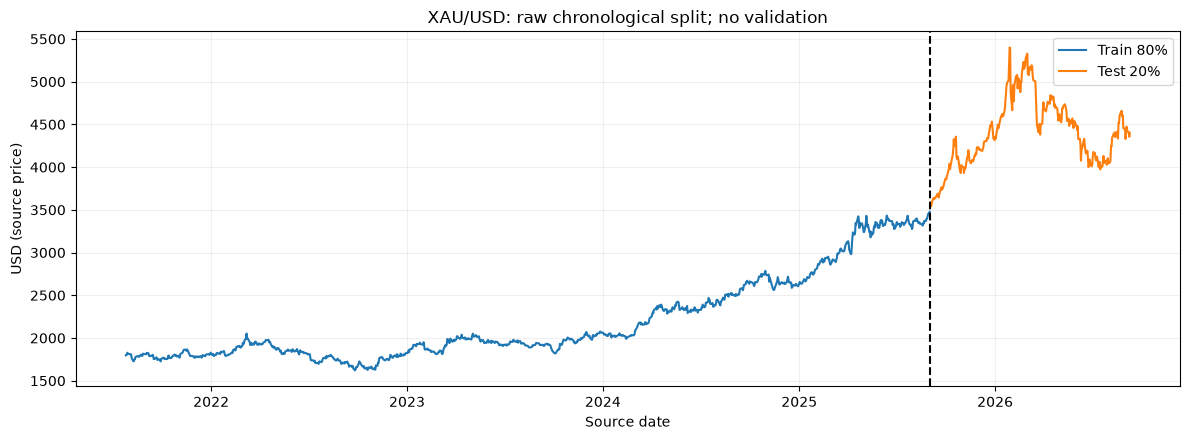

In [5]:
split_summary = pd.DataFrame([dict(partition=label, rows=b-a, start_date=df.index[a], end_date=df.index[b-1])
                             for label,a,b in [('Train',0,n_train),('Test',n_train,n)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots()
ax.plot(df.index[:n_train], prices[:n_train], label='Train 80%')
ax.plot(df.index[n_train:], prices[n_train:], label='Test 20%')
ax.axvline(df.index[n_train], color='black', linestyle='--')
ax.set(title=f'{ASSET_NAME}: raw chronological split; no validation', ylabel=UNIT, xlabel='Source date')
ax.legend(); save_figure(fig, '01_raw_split.png')

## 6. Descriptive EDA
These full-sample plots describe the supplied data; model settings remain the previously declared ones.

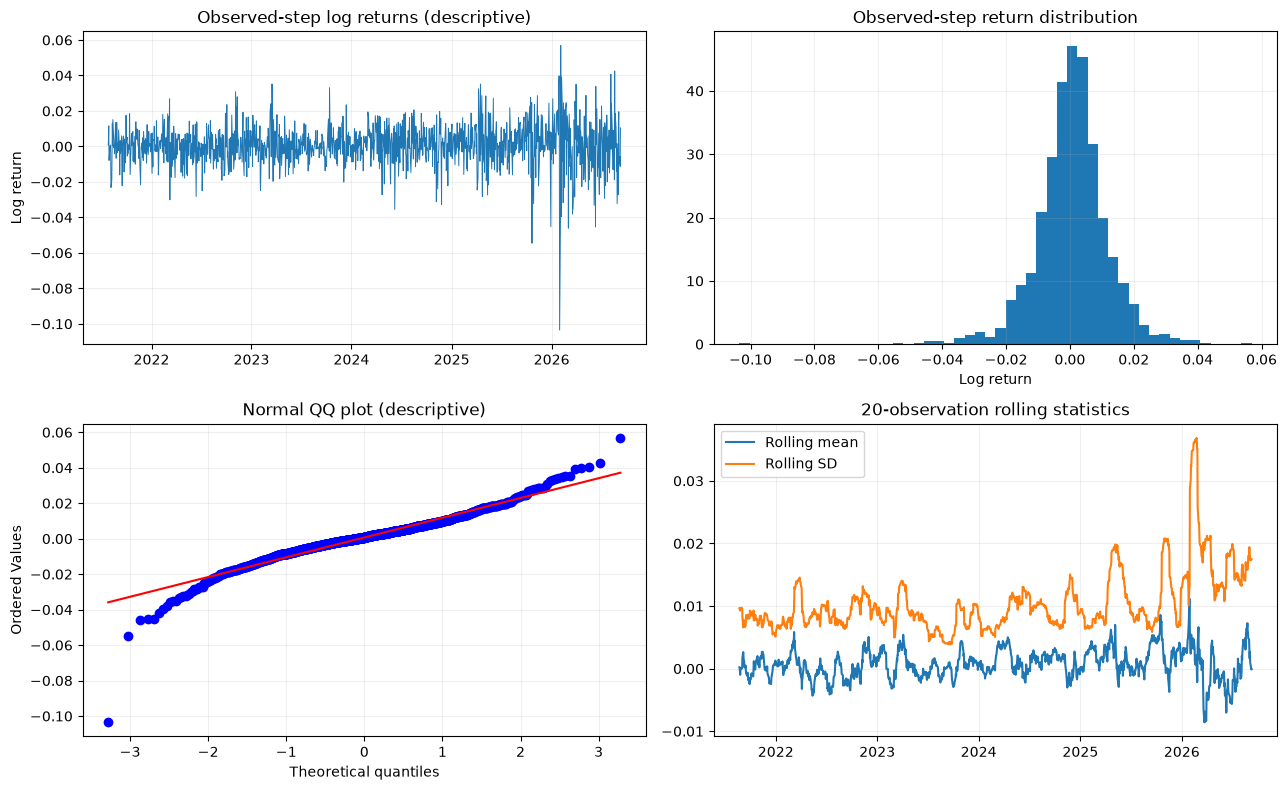

In [6]:
# Full-sample descriptive plots do not supply model settings or selection decisions.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(df.index[1:], returns[1:], linewidth=.7)
axes[0,0].set(title='Observed-step log returns (descriptive)', ylabel='Log return')
axes[0,1].hist(returns[1:], bins=50, density=True)
axes[0,1].set(title='Observed-step return distribution', xlabel='Log return')
stats.probplot(returns[1:], dist='norm', plot=axes[1,0])
axes[1,0].set_title('Normal QQ plot (descriptive)')
rolling = pd.Series(returns, index=df.index).rolling(ROLLING_WINDOW)
axes[1,1].plot(rolling.mean(), label='Rolling mean')
axes[1,1].plot(rolling.std(), label='Rolling SD')
axes[1,1].set_title(f'{ROLLING_WINDOW}-observation rolling statistics')
axes[1,1].legend(); save_figure(fig, '02_descriptive_eda.png')

## 7. Train stationarity and differencing
Use the smallest d=0,1,2 jointly supported by ADF (p<0.05) and KPSS (p>0.05). Stop if none qualifies. This is a Train-only rule.

,d,test,statistic,p_value,status,interpretation,warnings
0,0,ADF,1.049728,0.994764,FAIL,H0: unit root,FutureWarning: adfuller currently returns a pl...
1,0,KPSS,4.558009,0.010000,FAIL,H0: stationarity; p may be table bound,FutureWarning: adfuller currently returns a pl...
2,1,ADF,-24.619920,0.000000,PASS,H0: unit root,FutureWarning: adfuller currently returns a pl...
3,1,KPSS,0.353767,0.097083,PASS,H0: stationarity; p may be table bound,FutureWarning: adfuller currently returns a pl...


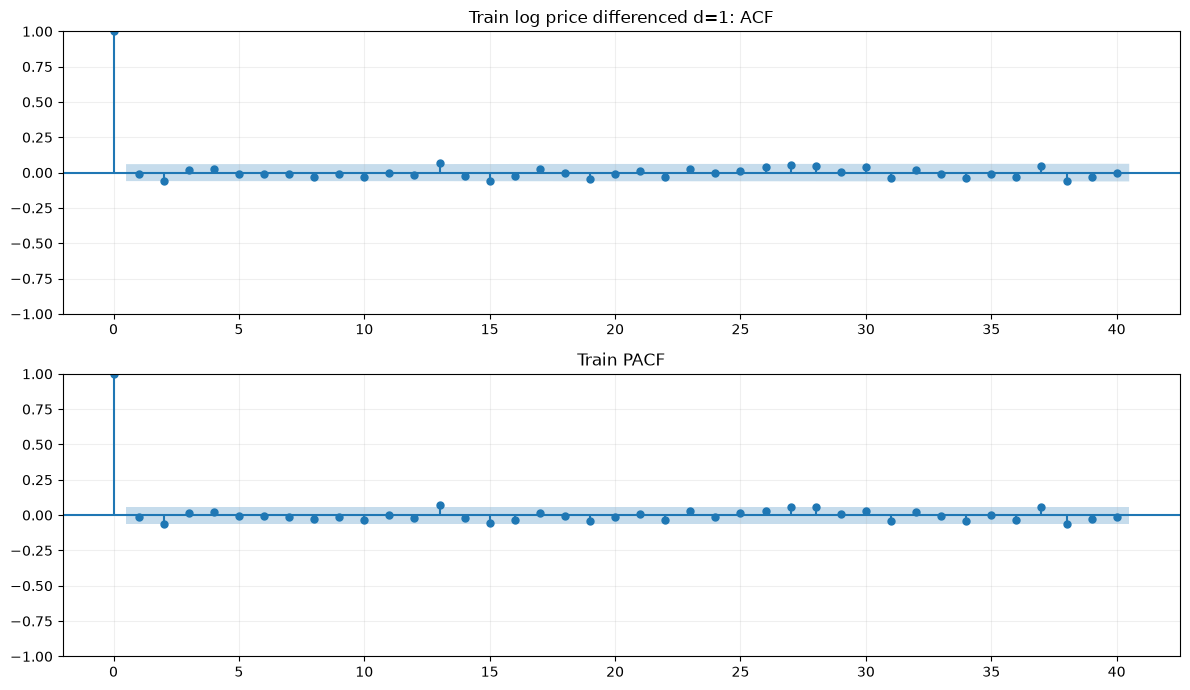

In [7]:
train_log = log_price[:n_train]
stationarity_rows=[]
d=None
for candidate_d in range(SETTINGS['max_d']+1):
    values=np.diff(train_log,n=candidate_d) if candidate_d else train_log
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf=adfuller(values,autolag='AIC')
        kp=kpss(values,regression='c',nlags='auto')
    supported=adf[1]<ALPHA and kp[1]>ALPHA
    stationarity_rows.extend([
        dict(d=candidate_d,test='ADF',statistic=adf[0],p_value=adf[1],status='PASS' if adf[1]<ALPHA else 'FAIL', interpretation='H0: unit root',warnings=warning_text(caught)),
        dict(d=candidate_d,test='KPSS',statistic=kp[0],p_value=kp[1],status='PASS' if kp[1]>ALPHA else 'FAIL', interpretation='H0: stationarity; p may be table bound',warnings=warning_text(caught))])
    if supported:
        d=candidate_d
        break
stationarity_tests=pd.DataFrame(stationarity_rows)
save_table(stationarity_tests,'stationarity_tests.csv'); display(stationarity_tests)
check('Train stationarity supports differencing', d is not None,
      'Smallest d jointly supported by ADF and KPSS; no Test-based changes.', statistic=d)
fig,axes=plt.subplots(2,1,figsize=(12,7))
plot_acf(values,lags=40,ax=axes[0]); plot_pacf(values,lags=40,method='ywm',ax=axes[1])
axes[0].set_title(f'Train log price differenced d={d}: ACF')
axes[1].set_title('Train PACF'); save_figure(fig,'03_train_acf_pacf.png')

## 8. Train ARIMA grid and diagnostics
The new-asset grid is p,q=0..3. Use no trend/constant at d=0, no trend/drift at d=1, and no trend at d=2. Select minimum AIC among converged finite-AIC fits with ARMA roots outside the unit circle. BIC, top three candidates, residual independence, ARCH, normality, mean and parameter significance are exported. Unlike the BTC task-specific shortlist gate, residual tests are reporting-only in this declared adaptation.

Completed Train ARIMA grid p=0


Completed Train ARIMA grid p=1


Completed Train ARIMA grid p=2


Completed Train ARIMA grid p=3


,model,p,d,q,trend,AIC,BIC,converged,roots_valid,warnings,error
0,"ARIMA(2,1,0) trend=t",2,1,0,t,-6938.274354,-6918.391433,True,True,,
2,"ARIMA(0,1,0) trend=t",0,1,0,t,-6938.034458,-6928.092998,True,True,,
3,"ARIMA(3,1,0) trend=t",3,1,0,t,-6936.512787,-6911.659137,True,True,,


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmod

,sample,check,statistic,p_value,status,interpretation
0,"ARIMA(2,1,0) trend=t",Ljung-Box lag 10,3.274771,9.159500e-01,REPORTED,No rejection of residual independence; model_d...
1,"ARIMA(2,1,0) trend=t",Ljung-Box lag 20,16.425641,5.628681e-01,REPORTED,No rejection of residual independence; model_d...
2,"ARIMA(2,1,0) trend=t",Ljung-Box lag 30,29.492155,3.878946e-01,REPORTED,No rejection of residual independence; model_d...
3,"ARIMA(2,1,0) trend=t",Residual mean t-test,0.010327,9.917623e-01,REPORTED,"Mean=2.9373893e-06; descriptive, dependent err..."
4,"ARIMA(2,1,0) trend=t",ARCH LM,70.618452,3.367450e-11,REPORTED,Conditional variance evidence; no retuning
5,"ARIMA(2,1,0) trend=t",Jarque-Bera,72.040796,2.272688e-16,REPORTED,Normality diagnostic; skew=0.01225; kurtosis=4...
6,"ARIMA(0,1,0) trend=t",Ljung-Box lag 10,7.338238,6.931737e-01,REPORTED,No rejection of residual independence; model_d...
7,"ARIMA(0,1,0) trend=t",Ljung-Box lag 20,21.601659,3.625108e-01,REPORTED,No rejection of residual independence; model_d...
8,"ARIMA(0,1,0) trend=t",Ljung-Box lag 30,32.814400,3.306532e-01,REPORTED,No rejection of residual independence; model_d...
9,"ARIMA(0,1,0) trend=t",Residual mean t-test,0.017525,9.860208e-01,REPORTED,"Mean=4.9948171e-06; descriptive, dependent err..."


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1066
Model:                 ARIMA(2, 1, 0)   Log Likelihood                3473.137
Date:                Sat, 10 Oct 2026   AIC                          -6938.274
Time:                        18:35:09   BIC                          -6918.391
Sample:                             0   HQIC                         -6930.741
                               - 1066                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0006      0.000      2.301      0.021    9.13e-05       0.001
ar.L1         -0.0122      0.027     -0.451      0.652      -0.065       0.041
ar.L2         -0.0621      0.026     -2.389      0.0

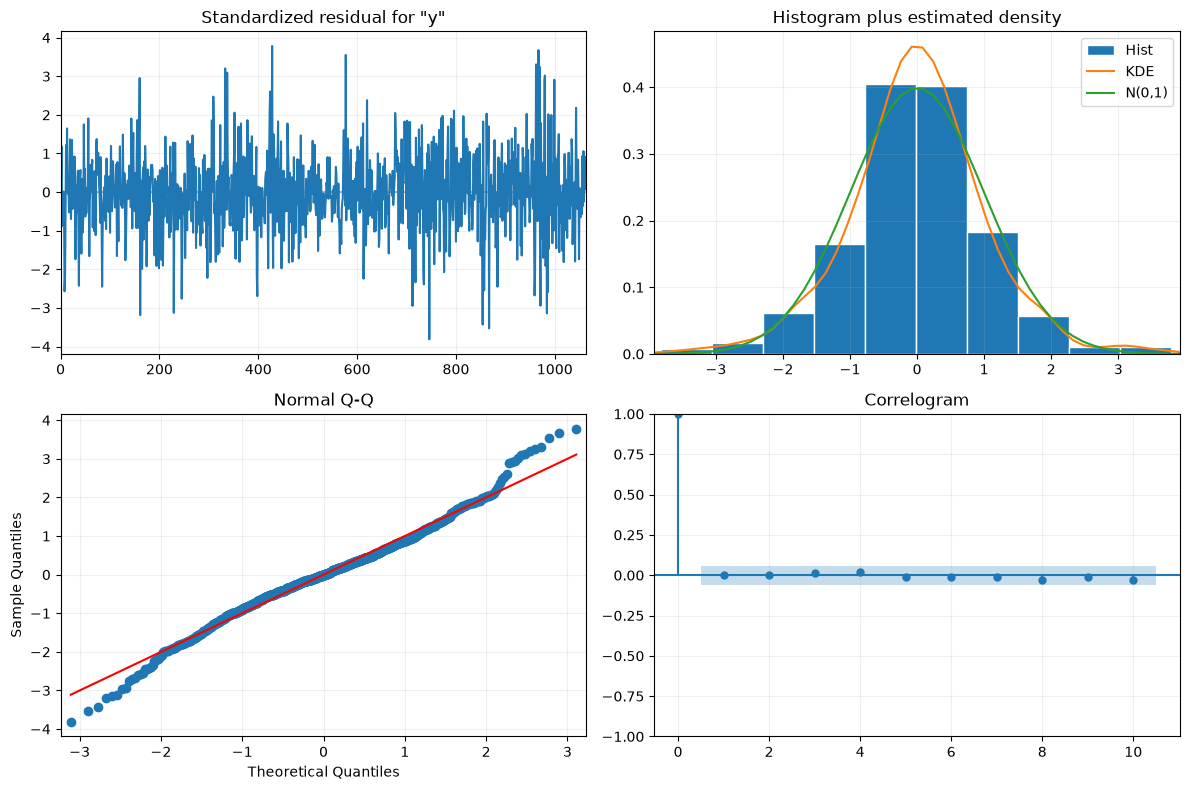

In [8]:
# The declared adaptation uses p,q=0..3 and AIC among converged root-valid fits.
# Ljung-Box, ARCH, mean and normality are reported, not added as post-hoc selection gates.
trends=['n','c'] if d==0 else (['n','t'] if d==1 else ['n'])
grid_rows=[]; fitted_models={}
for p in range(SETTINGS['max_p']+1):
    for q in range(SETTINGS['max_q']+1):
        for trend in trends:
            label=f'ARIMA({p},{d},{q}) trend={trend}'
            row=dict(model=label,p=p,d=d,q=q,trend=trend,AIC=np.nan,BIC=np.nan,converged=False,roots_valid=False,warnings='',error='')
            caught=[]
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    result=ARIMA(train_log,order=(p,d,q),trend=trend).fit(method_kwargs={'maxiter':SETTINGS['maxiter']})
                roots=np.r_[result.arroots,result.maroots]
                row.update(AIC=result.aic,BIC=result.bic,converged=bool(result.mle_retvals.get('converged',False)),
                           roots_valid=bool(np.isfinite(roots).all() and (np.abs(roots)>1).all()))
                fitted_models[label]=result
            except Exception as exc: row['error']=f'{type(exc).__name__}: {exc}'
            row['warnings']=warning_text(caught)
            grid_rows.append(row)
    print(f'Completed Train ARIMA grid p={p}',flush=True)
grid=pd.DataFrame(grid_rows).sort_values(['AIC','BIC','model'],na_position='last').reset_index(drop=True)
save_table(grid,'arima_grid.csv')
eligible=grid.loc[grid.converged & grid.roots_valid & np.isfinite(grid.AIC) & grid.error.eq('')]
check('Converged root-valid ARIMA candidate exists', not eligible.empty)
selected=eligible.iloc[0]
res=fitted_models[selected.model]
frozen_params=np.asarray(res.params).copy()
top=eligible.head(3).copy(); save_table(top,'arima_top_candidates.csv'); display(top)
diagnostics=[]; root_rows=[]; parameter_rows=[]
for row in top.itertuples(index=False):
    result=fitted_models[row.model]
    burn=max(int(result.loglikelihood_burn),int(getattr(result.filter_results,'nobs_diffuse',0)))
    diagnostics.append(residual_report(np.asarray(result.resid)[burn:],row.model,int(row.p+row.q)))
    for kind,roots in [('AR',result.arroots),('MA',result.maroots)]:
        if not len(roots): root_rows.append(dict(model=row.model,kind=kind,root=np.nan,modulus=np.nan,status='N/A',interpretation='No roots for this component'))
        for root in roots: root_rows.append(dict(model=row.model,kind=kind,root=str(root),modulus=abs(root),status='PASS' if abs(root)>1 else 'FAIL',interpretation='ARMA root modulus must exceed 1'))
    for name,value,se,pv in zip(result.param_names,result.params,result.bse,result.pvalues):
        parameter_rows.append(dict(model=row.model,parameter=name,estimate=value,standard_error=se,p_value=pv,status='REPORTED',interpretation='Parameter significance is not an additional selection gate'))
train_diagnostics=pd.concat(diagnostics,ignore_index=True)
save_table(train_diagnostics,'train_residual_diagnostics.csv'); display(train_diagnostics)
save_table(pd.DataFrame(root_rows),'arima_roots.csv')
save_table(pd.DataFrame(parameter_rows),'arima_parameters.csv')
res.save(MODEL_DIR/'arima_train.pkl')
write_json(MODEL_DIR/'selected_order.json',dict(order=[int(selected.p),d,int(selected.q)],trend=selected.trend,parameters=frozen_params.tolist(),fit_end_date=df.index[T],fit_n=n_train))
(SUMMARY_DIR/'model_summary.txt').write_text(res.summary().as_text(),encoding='utf-8')
print(res.summary())
fig=res.plot_diagnostics(figsize=(12,8)); save_figure(fig,'04_arima_train_diagnostics.png')
def model_fingerprint(): return hashlib.sha256(np.asarray(res.params).tobytes()).hexdigest()
frozen_state=model_fingerprint()

## 9. Rolling-origin Test forecast calculation
Origins start at the last Train row. At each origin, prior observed Test history may update inputs/filtering states. It never changes fitted coefficients, weights, scalers or tree structure. A horizon-h forecast does not use actuals between its origin and target. Targets are actual source dates at row origin+h.

In [9]:
forecast_rows=[]
for origin in range(T,n-1):
    # Refilter the history available at this origin; coefficients and variance stay frozen.
    state=res.apply(log_price[:origin+1],refit=False)
    np.testing.assert_array_equal(np.asarray(state.params),frozen_params)
    prediction=state.get_forecast(steps=MAX_H)
    mean=np.asarray(prediction.predicted_mean)
    bounds=np.asarray(prediction.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        if origin+h<n:
            forecast_rows.append(dict(h=h,origin_index=origin,target_index=origin+h,
                origin_date=df.index[origin],target_date=df.index[origin+h],price_origin=prices[origin],actual=prices[origin+h],
                forecast=np.exp(mean[h-1]),lower95=np.exp(bounds[h-1,0]),upper95=np.exp(bounds[h-1,1]),
                predicted_log_return=mean[h-1]-log_price[origin]))
forecasts=pd.DataFrame(forecast_rows)
seed_forecasts={}

## 10. Historical Test forecast tables
All rows appear in scrollable tables and are exported separately by horizon. ARIMA supplies model-based 95% intervals; log point forecasts are conditional medians. Other models have no calibrated intervals.

In [10]:
save_table(forecasts,'test_forecasts_all.csv')
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'### Historical Test forecasts: h={h} observations ({UNIT})'))
    show_table(group.drop(columns=['origin_index','target_index','predicted_log_return']))

### Historical Test forecasts: h=1 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
1,2025-09-01,2025-09-02,"3,476.470000","3,533.730000","3,476.485043","3,413.873811","3,540.244580"
1,2025-09-02,2025-09-03,"3,533.730000","3,559.430000","3,533.561004","3,469.921838","3,598.367327"
1,2025-09-03,2025-09-04,"3,559.430000","3,546.170000","3,557.860517","3,493.783719","3,623.112499"
1,2025-09-04,2025-09-05,"3,546.170000","3,586.810000","3,547.081397","3,483.198729","3,612.135687"
1,2025-09-05,2025-09-08,"3,586.810000","3,635.840000","3,589.517801","3,524.870858","3,655.350385"
1,2025-09-08,2025-09-09,"3,635.840000","3,626.480000","3,635.072138","3,569.604764","3,701.740199"
1,2025-09-09,2025-09-10,"3,626.480000","3,640.740000","3,625.935500","3,560.632677","3,692.435993"
1,2025-09-10,2025-09-11,"3,640.740000","3,634.090000","3,643.558453","3,577.938242","3,710.382155"
1,2025-09-11,2025-09-12,"3,634.090000","3,643.130000","3,635.689662","3,570.211167","3,702.369049"
1,2025-09-12,2025-09-15,"3,643.130000","3,679.130000","3,645.844506","3,580.183123","3,712.710134"


### Historical Test forecasts: h=3 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
3,2025-09-01,2025-09-04,"3,476.470000","3,546.170000","3,479.303180","3,374.482074","3,587.380332"
3,2025-09-02,2025-09-05,"3,533.730000","3,586.810000","3,534.679533","3,428.190101","3,644.476833"
3,2025-09-03,2025-09-08,"3,559.430000","3,635.840000","3,561.075466","3,453.790802","3,671.692699"
3,2025-09-04,2025-09-09,"3,546.170000","3,626.480000","3,552.494463","3,445.468319","3,662.845145"
3,2025-09-05,2025-09-10,"3,586.810000","3,640.740000","3,591.528942","3,483.326806","3,703.092148"
3,2025-09-08,2025-09-11,"3,635.840000","3,634.090000","3,636.882399","3,527.313897","3,749.854413"
3,2025-09-09,2025-09-12,"3,626.480000","3,643.130000","3,631.321297","3,521.920335","3,744.120568"
3,2025-09-10,2025-09-15,"3,640.740000","3,679.130000","3,647.265613","3,537.384295","3,760.560159"
3,2025-09-11,2025-09-16,"3,634.090000","3,689.800000","3,640.763301","3,531.077879","3,753.855867"
3,2025-09-12,2025-09-17,"3,643.130000","3,660.040000","3,649.884213","3,539.924005","3,763.260102"


### Historical Test forecasts: h=5 observations (USD (source price))

...

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
14,2025-09-01,2025-09-19,"3,476.470000","3,684.980000","3,503.034878","3,286.217050","3,734.157899"
14,2025-09-02,2025-09-22,"3,533.730000","3,746.470000","3,558.890145","3,338.615195","3,793.698381"
14,2025-09-03,2025-09-23,"3,559.430000","3,764.190000","3,585.344572","3,363.432245","3,821.898217"
14,2025-09-04,2025-09-24,"3,546.170000","3,736.290000","3,576.578651","3,355.208884","3,812.553938"
14,2025-09-05,2025-09-25,"3,586.810000","3,749.370000","3,616.080207","3,392.265519","3,854.661726"
14,2025-09-08,2025-09-26,"3,635.840000","3,760.240000","3,661.754320","3,435.112666","3,903.349323"
14,2025-09-09,2025-09-29,"3,626.480000","3,833.930000","3,655.947402","3,429.665163","3,897.159276"
14,2025-09-10,2025-09-30,"3,640.740000","3,858.510000","3,672.101209","3,444.819142","3,914.378878"
14,2025-09-11,2025-10-01,"3,634.090000","3,865.800000","3,665.473939","3,438.602062","3,907.314355"
14,2025-09-12,2025-10-02,"3,643.130000","3,856.530000","3,674.718393","3,447.274337","3,917.168739"


### Historical Test forecasts: h=21 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
21,2025-09-01,2025-09-30,"3,476.470000","3,858.510000","3,518.167662","3,254.143579","3,803.613270"
21,2025-09-02,2025-10-01,"3,533.730000","3,865.800000","3,574.264219","3,306.030319","3,864.261206"
21,2025-09-03,2025-10-02,"3,559.430000","3,856.530000","3,600.832927","3,330.605154","3,892.985559"
21,2025-09-04,2025-10-03,"3,546.170000","3,886.830000","3,592.029138","3,322.462053","3,883.467477"
21,2025-09-05,2025-10-06,"3,586.810000","3,961.090000","3,631.701337","3,359.157016","3,926.358469"
21,2025-09-08,2025-10-07,"3,635.840000","3,983.820000","3,677.572758","3,401.585975","3,975.951656"
21,2025-09-09,2025-10-08,"3,626.480000","4,038.900000","3,671.740755","3,396.191639","3,969.646475"
21,2025-09-10,2025-10-09,"3,640.740000","3,976.290000","3,687.964344","3,411.197715","3,987.186361"
21,2025-09-11,2025-10-10,"3,634.090000","4,018.300000","3,681.308446","3,405.041315","3,979.990438"
21,2025-09-12,2025-10-13,"3,643.130000","4,110.700000","3,690.592834","3,413.628948","3,990.028113"


### Historical Test forecasts: h=30 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast,lower95,upper95
30,2025-09-01,2025-10-13,"3,476.470000","4,110.700000","3,537.720197","3,223.328691","3,882.776282"
30,2025-09-02,2025-10-14,"3,533.730000","4,142.310000","3,594.128515","3,274.724093","3,944.686458"
30,2025-09-03,2025-10-15,"3,559.430000","4,208.580000","3,620.844881","3,299.066218","3,974.008639"
30,2025-09-04,2025-10-16,"3,546.170000","4,326.180000","3,611.992164","3,291.000228","3,964.292460"
30,2025-09-05,2025-10-17,"3,586.810000","4,249.980000","3,651.884845","3,327.347710","4,008.076125"
30,2025-09-08,2025-10-20,"3,635.840000","4,356.500000","3,698.011200","3,369.374891","4,058.701474"
30,2025-09-09,2025-10-21,"3,626.480000","4,125.100000","3,692.146785","3,364.031637","4,052.265066"
30,2025-09-10,2025-10-22,"3,640.740000","4,094.070000","3,708.460539","3,378.895614","4,070.170002"
30,2025-09-11,2025-10-23,"3,634.090000","4,126.170000","3,701.767650","3,372.797511","4,062.824314"
30,2025-09-12,2025-10-24,"3,643.130000","4,112.100000","3,711.103637","3,381.303824","4,073.070899"


## 11. Future forecasts from the latest observed origin
Same original Train parameters; no all-data refit. One row per horizon. Future dates are conditional weekday-pattern projections, explicitly distinct from observed historical target dates. No actual values or evaluation metrics exist for these rows.

In [11]:
# These are projected source-calendar dates, not verified exchange/holiday sessions.
future_dates=pd.date_range(df.index[-1]+calendar_offset,periods=MAX_H,freq=calendar_offset)
future_rows=[]
if MODEL=='ARIMA':
    latest_state=res.apply(log_price,refit=False)
    np.testing.assert_array_equal(latest_state.params,frozen_params)
    fc=latest_state.get_forecast(steps=MAX_H)
    means=np.asarray(fc.predicted_mean); intervals=np.asarray(fc.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=np.exp(means[h-1]),lower95=np.exp(intervals[h-1,0]),upper95=np.exp(intervals[h-1,1])))
else:
    latest,_=predict_cumulative(np.array([n-1]))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=prices[-1]*np.exp(latest[h][0])))
future_forecasts=pd.DataFrame(future_rows)
save_table(future_forecasts,'future_forecasts.csv')
display(Markdown('### Future forecasts: common latest origin; original Train fit'))
show_table(future_forecasts)
print('Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.')
check('Fitted model and preprocessing remain frozen', model_fingerprint()==frozen_state,
      'Includes SVR scalers, XGBoost trees, LSTM weights or full PatchTST state including BatchNorm buffers.')
if MODEL in ['SVR','LSTM','TRANSFORMER']:
    check('Input scaler remains frozen',joblib.hash(scaler)==scaler_hash)
write_json(MODEL_DIR/'frozen_state_audit.json',dict(before=frozen_state,after=model_fingerprint(),
    original_fit_end_date=df.index[T],latest_observed_input_date=df.index[-1],refit=False))

### Future forecasts: common latest origin; original Train fit

h,origin_date,target_date,target_date_status,price_origin,forecast,lower95,upper95
1,2026-09-09,2026-09-10,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,406.987321","4,327.617814","4,487.812484"
3,2026-09-09,2026-09-14,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,409.546363","4,276.699783","4,546.519539"
5,2026-09-09,2026-09-16,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,415.158575","4,247.086166","4,589.882212"
7,2026-09-09,2026-09-18,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,420.588621","4,223.562644","4,626.805709"
14,2026-09-09,2026-09-29,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,439.685795","4,164.894631","4,732.607113"
21,2026-09-09,2026-10-08,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,458.864825","4,124.245270","4,820.633649"
30,2026-09-09,2026-10-21,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,483.645368","4,085.191014","4,920.963480"


Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.


### 11.1 Daily future forecast tables - next 7 and 30 steps

Horizons count future observations. Dates retain the declared source-weekday pattern, including Sunday for WTI; they are conditional projections with holidays and source omissions unknown. These are not 7/30 elapsed calendar days.

Uses the existing ARIMA forecast path and model-based 95% intervals.

Exports `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under the existing model output directory.


In [12]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
future_forecast_daily['target_date_status'] = 'PROJECTED: weekday pattern, holidays/omissions unknown'
# Reuse the latest filtered state; its fitted Train parameters stay fixed.
np.testing.assert_array_equal(latest_state.params, frozen_params)
future_forecast_daily['forecast'] = np.exp(means[:daily_steps])
future_forecast_daily['lower95'] = np.exp(intervals[:daily_steps, 0])
future_forecast_daily['upper95'] = np.exp(intervals[:daily_steps, 1])
assert model_fingerprint() == frozen_state
assert (future_forecast_daily['lower95'] <= future_forecast_daily['forecast']).all()
assert (future_forecast_daily['forecast'] <= future_forecast_daily['upper95']).all()
daily_forecast_columns = ['forecast', 'lower95', 'upper95']
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['forecast', 'lower95', 'upper95']],
    future_forecasts.set_index('h').loc[HORIZONS, ['forecast', 'lower95', 'upper95']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} projected observations - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} {UNIT}**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all((TABLE_DIR/f'future_forecast_daily_{days}d.csv').is_file() for days in DAILY_FORECAST_WINDOWS)


**Next 7 projected observations - origin 2026-09-09, last observed price 4,401.550000 USD (source price)**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,lower95,upper95
2026-09-09,1,2026-09-10,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,406.987321","4,327.617814","4,487.812484"
2026-09-09,2,2026-09-11,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,406.967863","4,295.812606","4,520.999292"
2026-09-09,3,2026-09-14,Monday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,409.546363","4,276.699783","4,546.519539"
2026-09-09,4,2026-09-15,Tuesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,412.434184","4,260.984979","4,569.266384"
2026-09-09,5,2026-09-16,Wednesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,415.158575","4,247.086166","4,589.882212"
2026-09-09,6,2026-09-17,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,417.867524","4,234.723179","4,608.932541"
2026-09-09,7,2026-09-18,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,420.588621","4,223.562644","4,626.805709"


**Next 30 projected observations - origin 2026-09-09, last observed price 4,401.550000 USD (source price)**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,lower95,upper95
2026-09-09,1,2026-09-10,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,406.987321","4,327.617814","4,487.812484"
2026-09-09,2,2026-09-11,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,406.967863","4,295.812606","4,520.999292"
2026-09-09,3,2026-09-14,Monday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,409.546363","4,276.699783","4,546.519539"
2026-09-09,4,2026-09-15,Tuesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,412.434184","4,260.984979","4,569.266384"
2026-09-09,5,2026-09-16,Wednesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,415.158575","4,247.086166","4,589.882212"
2026-09-09,6,2026-09-17,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,417.867524","4,234.723179","4,608.932541"
2026-09-09,7,2026-09-18,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,420.588621","4,223.562644","4,626.805709"
2026-09-09,8,2026-09-21,Monday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,423.312331","4,213.347733","4,643.740137"
2026-09-09,9,2026-09-22,Tuesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,426.037056","4,203.908420","4,659.902658"
2026-09-09,10,2026-09-23,Wednesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,428.763409","4,195.121836","4,675.417329"


## 12. Process checks and RMSE/MAPE
Check all alignment, counts, unique origins, finite outputs and valid inverse transforms before scoring. Export offending rows and stop on failure; do not clip. Report RMSE in original units, MAPE in percent and sample size separately by horizon. Zero actuals make group MAPE undefined rather than changing the denominator.

In [13]:
def validate_forecasts(frame,label):
    cols=[c for c in ['actual','forecast','price_origin','lower95','upper95'] if c in frame]
    good=np.isfinite(frame[cols]).all(axis=1) & frame.forecast.gt(0)
    if 'actual' in frame: good &= frame.actual.gt(0)
    if 'lower95' in frame: good &= frame.lower95.gt(0) & frame.lower95.le(frame.forecast) & frame.forecast.le(frame.upper95)
    save_table(frame.loc[~good],f'{label}_offending_rows.csv')
    check(f'{label}: finite and valid log inversion',bool(good.all()),'No clipping or post-Test parameter revision.')
    check(f'{label}: unique origin/horizon',not frame.duplicated(['origin_date','h']).any())
    if 'target_index' in frame:
        check(f'{label}: target alignment',bool((frame.target_index==frame.origin_index+frame.h).all()) and
            (frame.target_index>=n_train).all() and (frame.target_index<n).all() and
            np.array_equal(pd.to_datetime(frame.target_date).to_numpy(),df.index[frame.target_index].to_numpy()) and
            np.array_equal(pd.to_datetime(frame.origin_date).to_numpy(),df.index[frame.origin_index].to_numpy()) and
            np.array_equal(frame.actual.to_numpy(),prices[frame.target_index]),
            'Dates come from actual observed row positions, never calendar-day addition.')
        for h in HORIZONS:
            check(f'{label}: h={h} count',int(frame.h.eq(h).sum())==n_test-h+1,statistic=int(frame.h.eq(h).sum()))
    else:
        check(f'{label}: future-only dates',bool((frame.target_date>df.index[-1]).all()) and len(frame)==len(HORIZONS))
validate_forecasts(forecasts,'test')
validate_forecasts(future_forecasts,'future')
def score(frame):
    rows=[]
    for h,g in frame.groupby('h',sort=True):
        actual=g.actual.to_numpy(); forecast=g.forecast.to_numpy()
        zero=int((actual==0).sum())
        rows.append(dict(h=h,n=len(g),first_target_date=g.target_date.min(),last_target_date=g.target_date.max(),
            RMSE=np.sqrt(np.mean((actual-forecast)**2)),MAPE=np.nan if zero else 100*np.mean(np.abs((actual-forecast)/actual)),
            zero_actuals=zero,RMSE_unit=UNIT,MAPE_unit='%'))
    return pd.DataFrame(rows)
evaluation=score(forecasts)
save_table(evaluation,'metrics_by_horizon.csv')
display(Markdown('### Historical Test RMSE and MAPE (after forecast tables)'))
display(evaluation)
seed_metrics=None
if seed_forecasts:
    frames=[]
    for seed,frame in seed_forecasts.items():
        validate_forecasts(frame,f'seed{seed}_test')
        save_table(frame,f'seed{seed}_test_forecasts.csv')
        metrics=score(frame); metrics.insert(0,'seed',seed); frames.append(metrics)
    seed_metrics=pd.concat(frames,ignore_index=True)
    save_table(seed_metrics,'seed_metrics.csv')
    seed_summary=seed_metrics.groupby('h').agg(RMSE_mean=('RMSE','mean'),RMSE_SD=('RMSE','std'),MAPE_mean=('MAPE','mean'),MAPE_SD=('MAPE','std')).reset_index()
    save_table(seed_summary,'seed_metric_summary.csv')
    display(Markdown('Individual seeds and sample SD (ddof=1); separate from return-space ensemble metrics'))
    display(seed_metrics); display(seed_summary)

### Historical Test RMSE and MAPE (after forecast tables)

,h,n,first_target_date,last_target_date,RMSE,MAPE,zero_actuals,RMSE_unit,MAPE_unit
0,1,267,2025-09-02,2026-09-09,80.838157,1.266946,0,USD (source price),%
1,3,265,2025-09-04,2026-09-09,136.595807,2.194446,0,USD (source price),%
2,5,263,2025-09-08,2026-09-09,173.493474,2.977007,0,USD (source price),%
3,7,261,2025-09-10,2026-09-09,204.239563,3.515312,0,USD (source price),%
4,14,254,2025-09-19,2026-09-09,277.390759,4.809476,0,USD (source price),%
5,21,247,2025-09-30,2026-09-09,331.101177,6.075630,0,USD (source price),%
6,30,238,2025-10-13,2026-09-09,399.171322,7.747665,0,USD (source price),%


## 13. Forecast plots and reporting-only Test residual diagnostics
Higher horizons can have overlapping errors and different target counts. Descriptive diagnostic p-values and Train/Test scale comparisons do not trigger model changes.

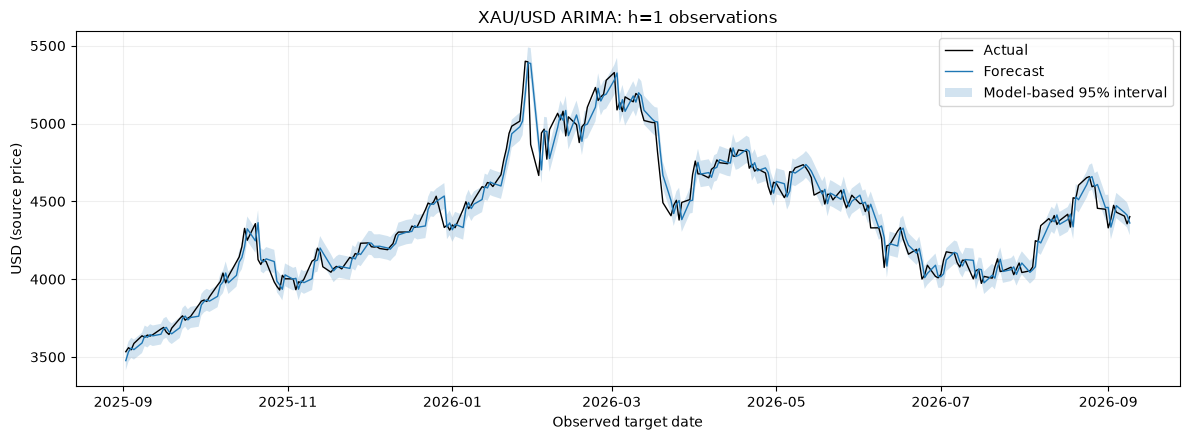

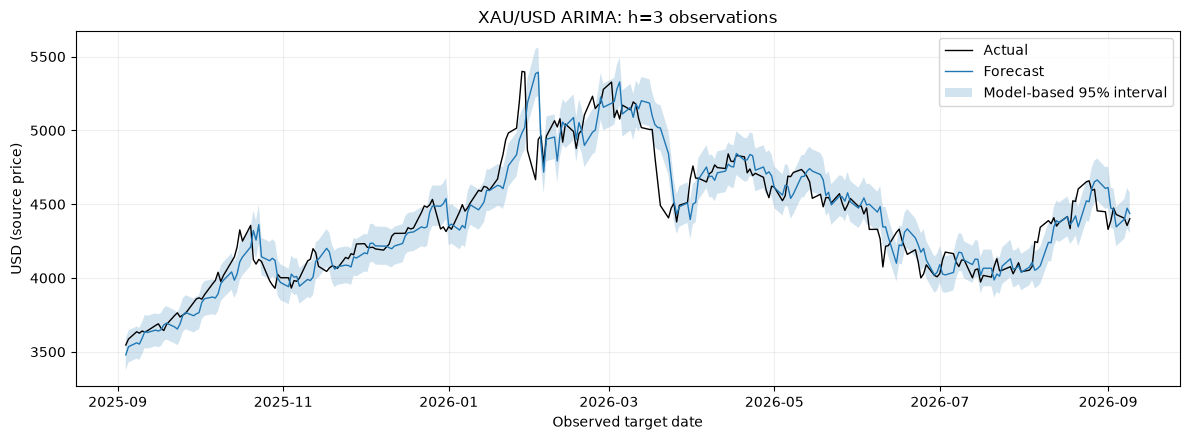

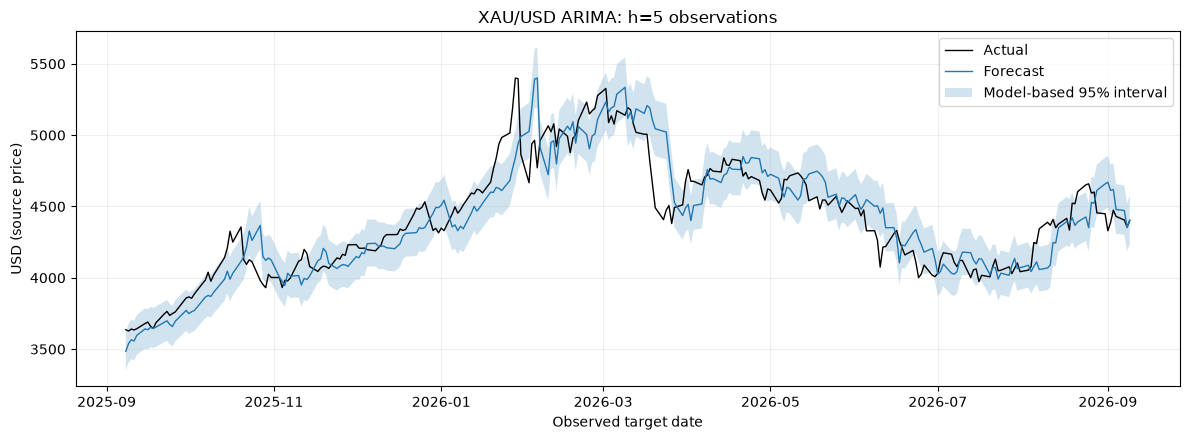

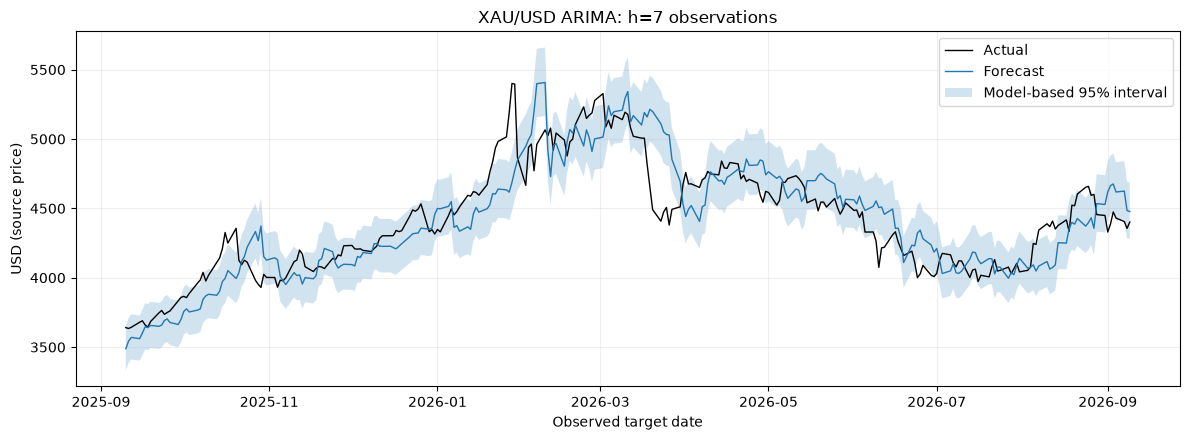

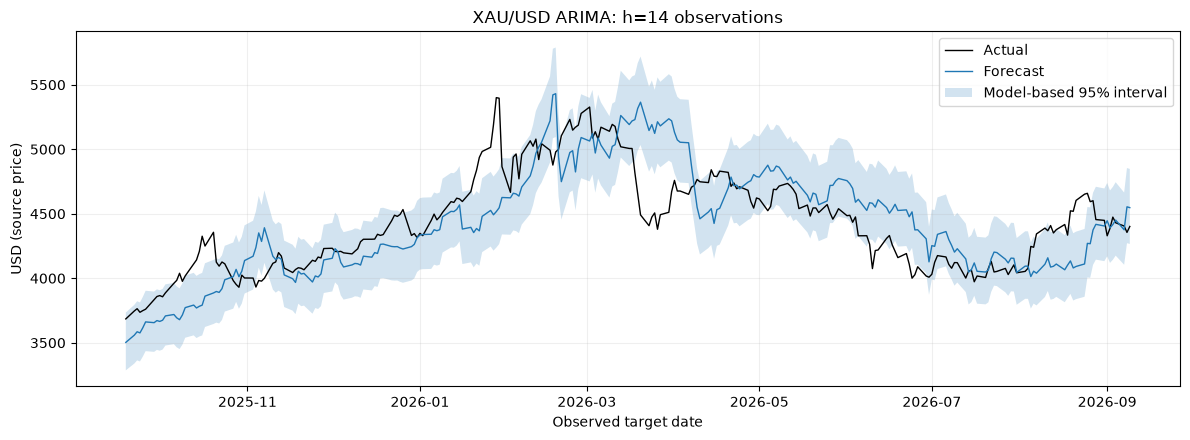

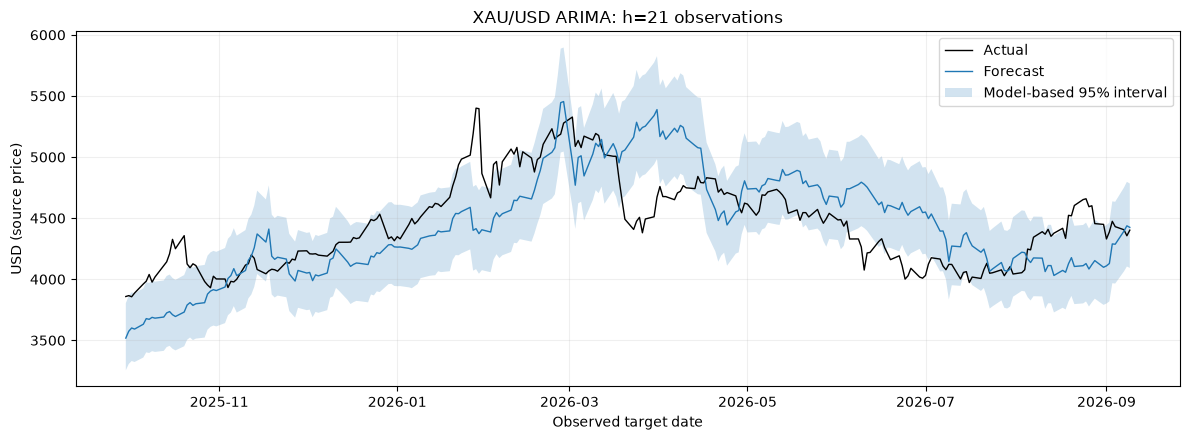

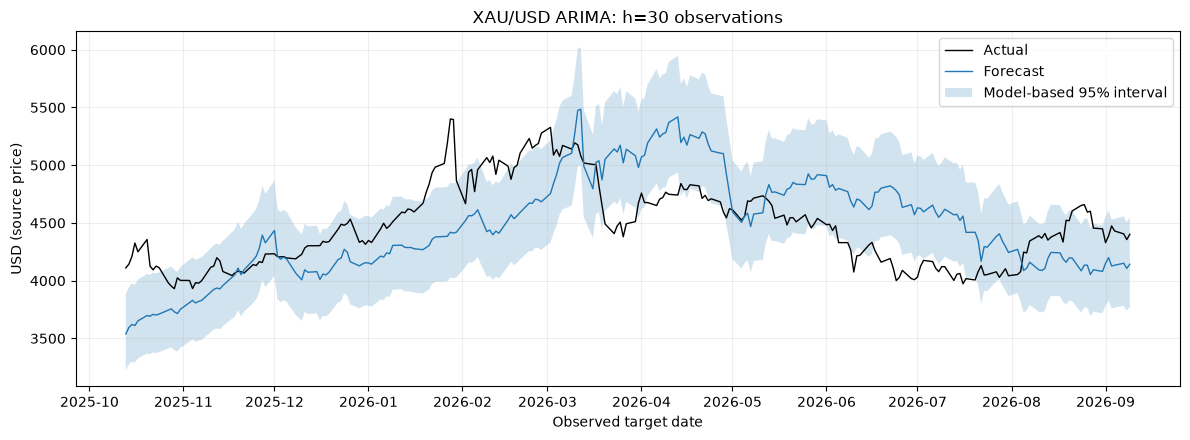

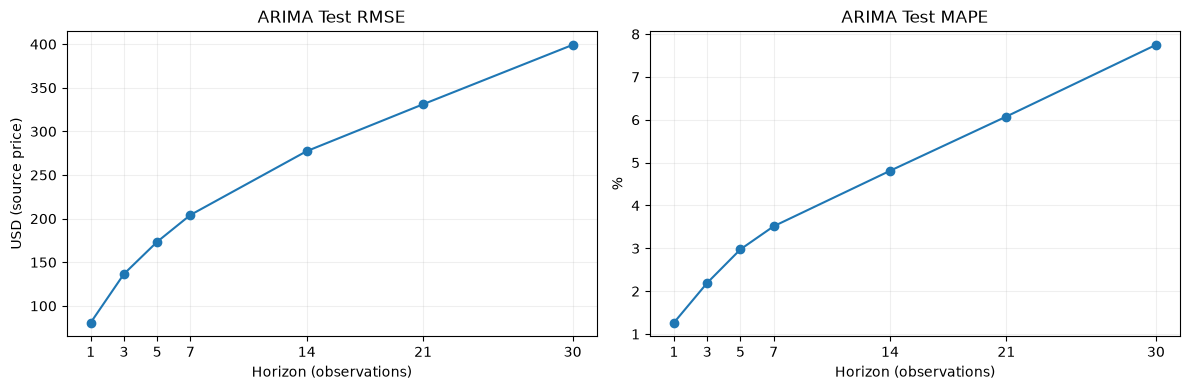

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 10,10.112363,4.306913e-01,REPORTED,No rejection of residual independence; model_d...
1,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 20,27.008550,1.350236e-01,REPORTED,No rejection of residual independence; model_d...
2,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 30,33.860286,2.864529e-01,REPORTED,No rejection of residual independence; model_d...
3,Test cumulative log-return errors h=1; reporti...,Residual mean t-test,0.271238,7.864183e-01,REPORTED,"Mean=0.00029184144; descriptive, dependent err..."
4,Test cumulative log-return errors h=1; reporti...,ARCH LM,18.803200,4.283473e-02,REPORTED,Conditional variance evidence; no retuning
5,Test cumulative log-return errors h=1; reporti...,Jarque-Bera,247.305098,1.987835e-54,REPORTED,Normality diagnostic; skew=-0.99382; kurtosis=...


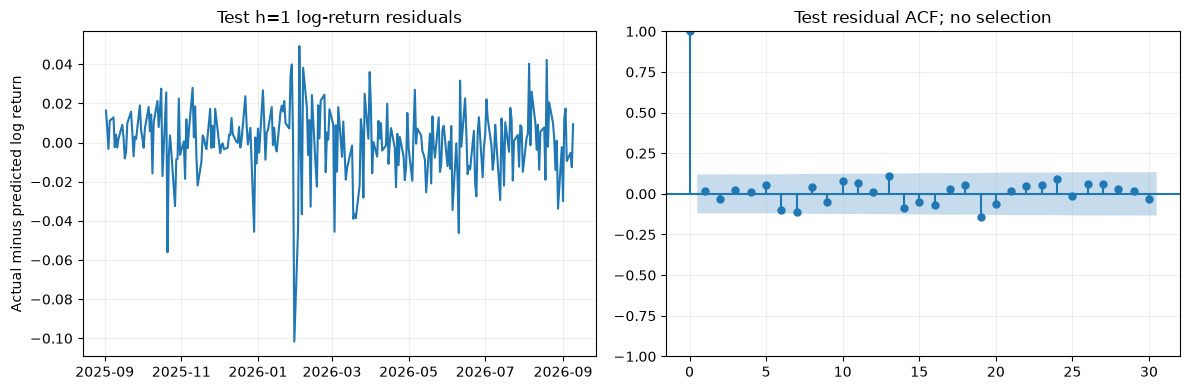

,sample,n,mean,SD,status
0,Train,1065,0.000619,0.009301,REPORTED
1,Test,267,0.000884,0.017648,REPORTED


In [14]:
for h in HORIZONS:
    g=forecasts.loc[forecasts.h.eq(h)].sort_values('target_date')
    fig,ax=plt.subplots()
    ax.plot(g.target_date,g.actual,label='Actual',color='black',linewidth=1)
    ax.plot(g.target_date,g.forecast,label='Forecast',linewidth=1)
    if 'lower95' in g: ax.fill_between(g.target_date,g.lower95,g.upper95,alpha=.2,label='Model-based 95% interval')
    ax.set(title=f'{ASSET_NAME} {MODEL}: h={h} observations',xlabel='Observed target date',ylabel=UNIT)
    ax.legend(); save_figure(fig,f'test_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],[UNIT,'%']):
    ax.plot(evaluation.h,evaluation[metric],marker='o')
    ax.set(title=f'{MODEL} Test {metric}',xlabel='Horizon (observations)',ylabel=unit,xticks=HORIZONS)
save_figure(fig,'metrics_by_horizon.png')
hdiag=HORIZONS[0]
g=forecasts.loc[forecasts.h.eq(hdiag)].sort_values('origin_date')
errors=np.log(g.actual/g.price_origin)-g.predicted_log_return
test_diagnostics=residual_report(errors,f'Test cumulative log-return errors h={hdiag}; reporting only')
save_table(test_diagnostics,'test_residual_diagnostics.csv'); display(test_diagnostics)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(g.target_date,errors); axes[0].set(title=f'Test h={hdiag} log-return residuals',ylabel='Actual minus predicted log return')
plot_acf(errors,lags=min(30,len(errors)//4),ax=axes[1]); axes[1].set_title('Test residual ACF; no selection')
save_figure(fig,'test_residual_diagnostics.png')
scale_comparison=pd.DataFrame([dict(sample='Train',n=n_train-1,mean=np.mean(returns[1:n_train]),SD=np.std(returns[1:n_train],ddof=1),status='REPORTED'),
    dict(sample='Test',n=n_test,mean=np.mean(returns[n_train:]),SD=np.std(returns[n_train:],ddof=1),status='REPORTED')])
save_table(scale_comparison,'return_scale_comparison.csv'); display(scale_comparison)

## 14. Summary generated from this execution
Rerunning regenerates this report from current results; there is no copied saved-result markdown.

In [15]:
lines=[f'# {ASSET_NAME} - {MODEL}: results from this execution','',
    f'Source: `{DATA_PATH.name}`; target: {TARGET_COL}; units: {UNIT}.',ASSET_NOTE,'',
    f'Raw chronological Train/Test: {n_train}/{n_test}; no validation.',
    f'Train: {df.index[0].date()} to {df.index[T].date()}; Test: {df.index[n_train].date()} to {df.index[-1].date()}.',
    f'Horizons: {HORIZONS} observations. Lookback: {LOOKBACK} observed returns for window models.',CALENDAR_NOTE,
    f'Source calendar audit: {len(missing_dates)} dates absent relative to the declared weekday pattern; maximum gap {int(gaps.calendar_days.max())} calendar days.',
    'Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.',
    'Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.','',
    '## Model development']
if MODEL=='ARIMA':
    lines += [f'Selected {selected.model}; Train AIC={selected.AIC:.6f}; BIC={selected.BIC:.6f}.',
        'Differencing is the smallest Train ADF/KPSS-supported order. Selection uses AIC among converged fits with valid roots. Residual tests are reported without retuning.',
        'Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means. The 95% intervals are model-based; ARCH/non-normality and calendar irregularity limit interpretation.']
    if int(selected.p)==0 and d==1 and int(selected.q)==0 and selected.trend=='n':
        lines.append('ARIMA(0,1,0) without drift gives the latest observed price as the point forecast; uncertainty increases with horizon.')
elif MODEL=='SVR':
    lines += ['Direct cumulative-log-return RBF models use the fixed Train-only C/epsilon heuristic and Train input/target scalers. No hyperparameter cross-validation.']
elif MODEL=='XGBOOST':
    lines += ['Direct cumulative-log-return models use a fixed predeclared configuration. Learning curves are fitting data only. Raw gain is neither causal importance nor proof of future usefulness.']
else:
    lines += [f'MIMO predicts the next {MAX_H} individual observed-step log returns; prices compound the predicted path only.',
        f'All predefined seeds {SEEDS} are included equally; {EPOCHS} fixed epochs each. Average inverse-scaled returns before compounding.',
        'Ensemble metrics are not the mean seed metrics. Seed metric SD uses ddof=1 and is not a prediction interval.']
lines += ['', '## Historical Test metrics',markdown_table(evaluation),'',
    'Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.',
    'MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.',
    '', '## Future forecasts (no actuals or metrics)',markdown_table(future_forecasts),'',
    'Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.',
    '', '## Checks and limitations',
    f'Process checks: {sum(row["status"]=="PASS" for row in process_rows)} passed; {sum(row["status"]=="FAIL" for row in process_rows)} failed.',
    'Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.',
    'No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.',
    'Test findings did not change parameters, epochs, transformations, seeds, or model selection.',
    'These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.',
    f'All rows, figures, summaries and fitted artifacts are under OUTPUT/{MODEL}_{ASSET}/.',
    f'Tested Python executable: {sys.executable}.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary='\n\n'.join(lines)
(SUMMARY_DIR/'execution_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
write_json(SUMMARY_DIR/'execution_audit.json',dict(completed=True,asset=ASSET,model=MODEL,
    n=n,n_train=n_train,n_test=n_test,horizons=HORIZONS,counts={int(h):int(c) for h,c in forecasts.groupby('h').size().items()},
    train_end=str(df.index[T].date()),test_start=str(df.index[n_train].date()),last_observation=str(df.index[-1].date()),
    parameters_frozen=model_fingerprint()==frozen_state,process_checks=process_rows,
    source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),seed_count=len(seed_forecasts),python_executable=sys.executable))

# XAU/USD - ARIMA: results from this execution



Source: `XAU_USD Historical Data.csv`; target: Price; units: USD (source price).

The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.



Raw chronological Train/Test: 1066/267; no validation.

Train: 2021-07-26 to 2025-09-01; Test: 2025-09-02 to 2026-09-09.

Horizons: [1, 3, 5, 7, 14, 21, 30] observations. Lookback: 40 observed returns for window models.

Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.

Source calendar audit: 5 dates absent relative to the declared weekday pattern; maximum gap 4 calendar days.

Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.

Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.



## Model development

Selected ARIMA(2,1,0) trend=t; Train AIC=-6938.274354; BIC=-6918.391433.

Differencing is the smallest Train ADF/KPSS-supported order. Selection uses AIC among converged fits with valid roots. Residual tests are reported without retuning.

Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means. The 95% intervals are model-based; ARCH/non-normality and calendar irregularity limit interpretation.



## Historical Test metrics

| h | n | first_target_date | last_target_date | RMSE | MAPE | zero_actuals | RMSE_unit | MAPE_unit |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 267 | 2025-09-02 00:00:00 | 2026-09-09 00:00:00 | 80.838157 | 1.266946 | 0 | USD (source price) | % |
| 3 | 265 | 2025-09-04 00:00:00 | 2026-09-09 00:00:00 | 136.595807 | 2.194446 | 0 | USD (source price) | % |
| 5 | 263 | 2025-09-08 00:00:00 | 2026-09-09 00:00:00 | 173.493474 | 2.977007 | 0 | USD (source price) | % |
| 7 | 261 | 2025-09-10 00:00:00 | 2026-09-09 00:00:00 | 204.239563 | 3.515312 | 0 | USD (source price) | % |
| 14 | 254 | 2025-09-19 00:00:00 | 2026-09-09 00:00:00 | 277.390759 | 4.809476 | 0 | USD (source price) | % |
| 21 | 247 | 2025-09-30 00:00:00 | 2026-09-09 00:00:00 | 331.101177 | 6.075630 | 0 | USD (source price) | % |
| 30 | 238 | 2025-10-13 00:00:00 | 2026-09-09 00:00:00 | 399.171322 | 7.747665 | 0 | USD (source price) | % |



Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.

MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.



## Future forecasts (no actuals or metrics)

| h | origin_date | target_date | target_date_status | price_origin | forecast | lower95 | upper95 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 2026-09-09 00:00:00 | 2026-09-10 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4406.987321 | 4327.617814 | 4487.812484 |
| 3 | 2026-09-09 00:00:00 | 2026-09-14 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4409.546363 | 4276.699783 | 4546.519539 |
| 5 | 2026-09-09 00:00:00 | 2026-09-16 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4415.158575 | 4247.086166 | 4589.882212 |
| 7 | 2026-09-09 00:00:00 | 2026-09-18 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4420.588621 | 4223.562644 | 4626.805709 |
| 14 | 2026-09-09 00:00:00 | 2026-09-29 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4439.685795 | 4164.894631 | 4732.607113 |
| 21 | 2026-09-09 00:00:00 | 2026-10-08 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4458.864825 | 4124.245270 | 4820.633649 |
| 30 | 2026-09-09 00:00:00 | 2026-10-21 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4483.645368 | 4085.191014 | 4920.963480 |



Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.



## Checks and limitations

Process checks: 19 passed; 0 failed.

Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.

No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.

Test findings did not change parameters, epochs, transformations, seeds, or model selection.

These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.

All rows, figures, summaries and fitted artifacts are under OUTPUT/ARIMA_XAU/.

Tested Python executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe.



**Daily future forecasts**

Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

## Implementation reference
- Local reference: `../BTC_TEST/ARIMA_BTC.ipynb` (read only; not rerun or modified).
- User protocol: `C:/Users/User/.codex/skills/time-series-forecasting/SKILL.md` and its asset-adaptation/model references.
- These notebooks adapt the local implementation; they do not claim replication of a separately tuned external study.